In [1]:

!pip install -q gradio plotly scikit-learn pandas numpy matplotlib seaborn
print("All libraries installed successfully!")


All libraries installed successfully!


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import gradio as gr

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Generate sample dataset
np.random.seed(42)
n = 5000

df = pd.DataFrame({
    "Age": np.random.randint(18, 60, n),
    "Episode_Length": np.random.randint(15, 120, n),
    "Genre": np.random.choice(
        ["Technology", "Comedy", "Health", "Education", "Sports"], n),
    "Listening_Platform": np.random.choice(
        ["Spotify", "Apple Podcasts", "YouTube", "Amazon Music"], n),
    "Episode_Number": np.random.randint(1, 200, n),
    "Host_Popularity": np.random.randint(1, 101, n),
    "Number_of_Ads": np.random.randint(0, 6, n),
    "Age_Group": np.random.choice(
        ["Young", "Adult", "Middle Age"], n)
})

# Generate listening time
df["Listening_Time"] = (
    df["Episode_Length"] * 0.55
    + df["Host_Popularity"] * 0.12
    + df["Episode_Number"] * 0.025
    - df["Number_of_Ads"] * 2.5
    + np.random.normal(0, 7, n)
)

# Listening time cannot exceed episode length
df["Listening_Time"] = np.clip(
    df["Listening_Time"], 1, df["Episode_Length"]
)

df["Listening_Time"] = df["Listening_Time"].round(2)

print("Dataset created successfully!")
print("Dataset Shape:", df.shape)
display(df.head())


Dataset created successfully!
Dataset Shape: (5000, 9)


,Age,Episode_Length,Genre,Listening_Platform,Episode_Number,Host_Popularity,Number_of_Ads,Age_Group,Listening_Time
0,56,33,Comedy,Spotify,98,83,0,Young,21.64
1,46,34,Technology,Spotify,47,44,0,Young,19.61
2,32,114,Comedy,Amazon Music,81,57,4,Young,57.68
3,25,49,Comedy,YouTube,39,66,3,Adult,25.18
4,38,46,Comedy,Amazon Music,38,81,5,Adult,30.47


In [3]:

# Dataset information
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

# Remove duplicates and missing values
df = df.drop_duplicates()
df = df.dropna()

print("\nCleaned Dataset Shape:", df.shape)


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5000 non-null   int64  
 1   Episode_Length      5000 non-null   int64  
 2   Genre               5000 non-null   object 
 3   Listening_Platform  5000 non-null   object 
 4   Episode_Number      5000 non-null   int64  
 5   Host_Popularity     5000 non-null   int64  
 6   Number_of_Ads       5000 non-null   int64  
 7   Age_Group           5000 non-null   object 
 8   Listening_Time      5000 non-null   float64
dtypes: float64(1), int64(5), object(3)
memory usage: 351.7+ KB

Missing Values:
Age                   0
Episode_Length        0
Genre                 0
Listening_Platform    0
Episode_Number        0
Host_Popularity       0
Number_of_Ads         0
Age_Group             0
Listening_Time        0
dtype: int64

Duplicate Records: 0

S

,Age,Episode_Length,Episode_Number,Host_Popularity,Number_of_Ads,Listening_Time
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,38.662200,67.062400,100.405400,50.370600,2.541400,38.974322
std,12.028492,30.202638,57.238263,28.987096,1.697899,18.979161
min,18.000000,15.000000,1.000000,1.000000,0.000000,1.000000
25%,28.000000,40.000000,51.000000,26.000000,1.000000,23.910000
50%,39.000000,67.000000,100.000000,50.000000,3.000000,38.930000
75%,49.000000,93.000000,150.000000,76.000000,4.000000,53.750000
max,59.000000,119.000000,199.000000,100.000000,5.000000,100.310000



Cleaned Dataset Shape: (5000, 9)


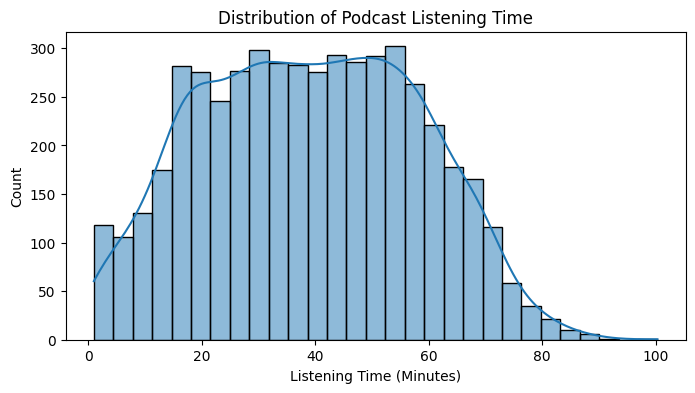

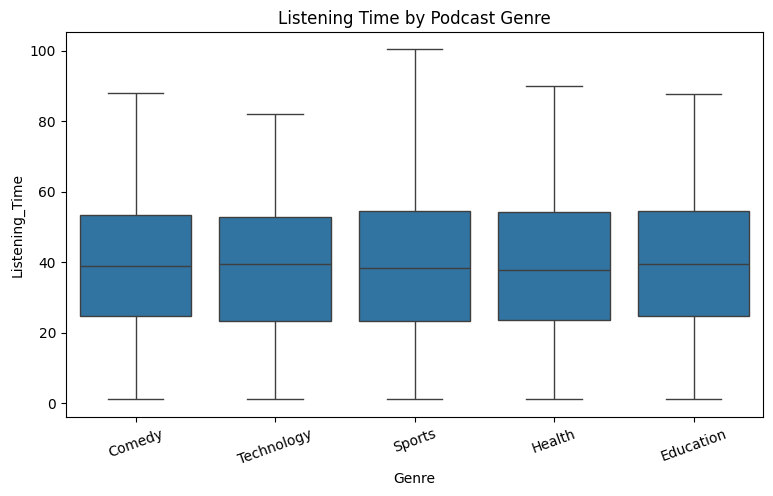

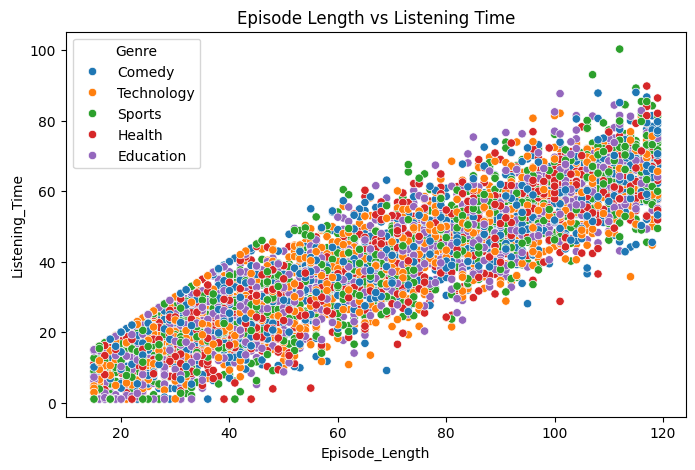

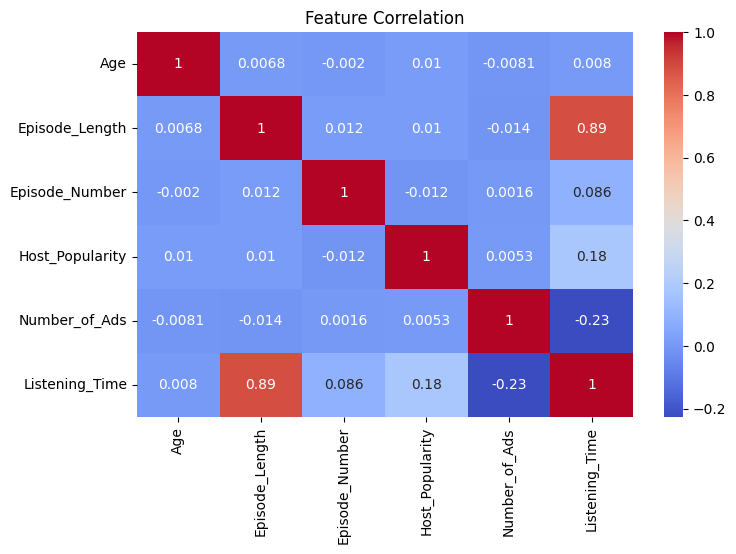

In [4]:

# 1. Listening time distribution
plt.figure(figsize=(8, 4))
sns.histplot(df["Listening_Time"], kde=True)
plt.title("Distribution of Podcast Listening Time")
plt.xlabel("Listening Time (Minutes)")
plt.show()

# 2. Listening time by genre
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Genre", y="Listening_Time")
plt.title("Listening Time by Podcast Genre")
plt.xticks(rotation=20)
plt.show()

# 3. Episode length vs listening time
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df, x="Episode_Length", y="Listening_Time",
    hue="Genre"
)
plt.title("Episode Length vs Listening Time")
plt.show()

# 4. Correlation heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True, cmap="coolwarm"
)
plt.title("Feature Correlation")
plt.show()


In [5]:

# Separate input features and target
X = df.drop("Listening_Time", axis=1)
y = df["Listening_Time"]

# Identify categorical and numerical columns
categorical = X.select_dtypes(include="object").columns.tolist()
numerical = X.select_dtypes(include="number").columns.tolist()

# Convert categorical values into numerical values
preprocessor = ColumnTransformer([
    ("category", OneHotEncoder(handle_unknown="ignore"), categorical),
    ("number", "passthrough", numerical)
])

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train three models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=12, random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=150, max_depth=15, random_state=42, n_jobs=-1
    )
}

trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

print("All three models trained successfully!")


All three models trained successfully!


,Model,R2 Score (%),MAE,RMSE
0,Linear Regression,88.07,5.17,6.51
1,Decision Tree,75.55,7.38,9.32
2,Random Forest,86.94,5.40,6.81


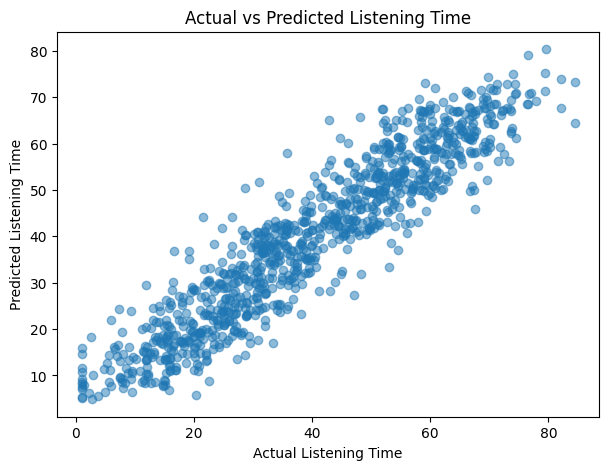

Random Forest evaluation completed!


In [6]:

results = []

for name, model in trained_models.items():
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "R2 Score (%)": round(r2_score(y_test, predictions) * 100, 2),
        "MAE": round(mean_absolute_error(y_test, predictions), 2),
        "RMSE": round(np.sqrt(mean_squared_error(y_test, predictions)), 2)
    })

results_df = pd.DataFrame(results)
display(results_df)

# Select Random Forest as the main model
best_model = trained_models["Random Forest"]

# Actual vs predicted chart
predictions = best_model.predict(X_test)

plt.figure(figsize=(7, 5))
plt.scatter(y_test, predictions, alpha=0.5)
plt.xlabel("Actual Listening Time")
plt.ylabel("Predicted Listening Time")
plt.title("Actual vs Predicted Listening Time")
plt.show()

print("Random Forest evaluation completed!")


In [8]:

# Chart 1: Average listening time by genre
fig1 = px.bar(
    df.groupby("Genre", as_index=False)["Listening_Time"].mean(),
    x="Genre", y="Listening_Time",
    color="Genre",
    title="Average Listening Time by Genre",
    template="plotly_white"
)

# Chart 2: Listening time distribution
fig2 = px.histogram(
    df, x="Listening_Time",
    color="Genre", nbins=30,
    title="Podcast Listening Time Distribution",
    template="plotly_white"
)

# Chart 3: Episode length vs listening time
fig3 = px.scatter(
    df, x="Episode_Length", y="Listening_Time",
    color="Genre",
    title="Episode Length vs Listening Time",
    template="plotly_white"
)

# Chart 4: Model comparison
fig4 = px.bar(
    results_df, x="Model", y="R2 Score (%)",
    color="Model",
    title="Machine Learning Model Comparison",
    template="plotly_white"
)

print("All dashboard charts are ready!")


All dashboard charts are ready!


In [ ]:

def predict_listening_time(
    age, episode_length, genre, platform,
    episode_number, popularity, ads, age_group
):
    input_data = pd.DataFrame([{
        "Age": age,
        "Episode_Length": episode_length,
        "Genre": genre,
        "Listening_Platform": platform,
        "Episode_Number": episode_number,
        "Host_Popularity": popularity,
        "Number_of_Ads": ads,
        "Age_Group": age_group
    }])

    prediction = best_model.predict(input_data)[0]

    prediction = min(max(prediction, 0), episode_length)

    return (
        f"Predicted Listening Time: {prediction:.2f} minutes\n\n"
        f"Episode Length: {episode_length} minutes\n"
        f"Expected Listening Percentage: "
        f"{(prediction / episode_length) * 100:.1f}%"
    )


with gr.Blocks(theme=gr.themes.Soft(), title="Podcast Analytics") as demo:

    gr.Markdown("""
    # 🎧 Podcast Listening Time Prediction
    ### Machine Learning Based Podcast Analytics Dashboard

    Analyze listening behaviour and predict how long
    a user will listen to a podcast episode.
    """)

    with gr.Tab("📊 Analytics Dashboard"):

        gr.Markdown("### Podcast Data Analysis")

        with gr.Row():
            gr.Plot(fig1)
            gr.Plot(fig2)

        with gr.Row():
            gr.Plot(fig3)
            gr.Plot(fig4)

        gr.Markdown("### Model Performance Comparison")
        gr.Dataframe(results_df)

    with gr.Tab("🤖 Predict Listening Time"):

        gr.Markdown("### Enter Podcast Details")

        with gr.Row():
            age = gr.Number(label="User Age", value=25)
            episode_length = gr.Number(
                label="Episode Length (Minutes)", value=60
            )

        with gr.Row():
            genre = gr.Dropdown(
                ["Technology", "Comedy", "Health",
                 "Education", "Sports"],
                label="Podcast Genre",
                value="Technology"
            )

            platform = gr.Dropdown(
                ["Spotify", "Apple Podcasts",
                 "YouTube", "Amazon Music"],
                label="Listening Platform",
                value="Spotify"
            )

        with gr.Row():
            episode_number = gr.Number(
                label="Episode Number", value=10
            )
            popularity = gr.Slider(
                1, 100, value=70,
                label="Host Popularity"
            )

        with gr.Row():
            ads = gr.Slider(
                0, 5, value=2,
                step=1, label="Number of Advertisements"
            )

            age_group = gr.Dropdown(
                ["Young", "Adult", "Middle Age"],
                label="Age Group",
                value="Adult"
            )

        predict_button = gr.Button(
            "Predict Listening Time 🚀",
            variant="primary"
        )

        output = gr.Textbox(
            label="Prediction Result",
            lines=4
        )

        predict_button.click(
            fn=predict_listening_time,
            inputs=[
                age, episode_length, genre, platform,
                episode_number, popularity, ads, age_group
            ],
            outputs=output
        )

    gr.Markdown("""
    ---
    **Project:** Podcast Listening Time Prediction
    **Algorithm:** Random Forest Regressor
    **Developed using:** Python, Machine Learning and Google Colab
    """)

# Launch dashboard
demo.launch(share=True, debug=True)


/tmp/ipykernel_1164/2463106315.py:28: UserWarning:

The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.



Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://8feef561ce673ef488.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
